# Classification de sentiments avec BiLSTM et SetFit

Cette preuve de concept compare un BiLSTM avec GloVe et SetFit avec MPNet sur les tweets anglais de Sentiment140. Le critère principal est le F1 macro. On compare aussi l'accuracy, les erreurs par classe, le nombre de données utilisées et les temps de calcul.

Les modèles sauvegardés sont rechargés avec `REUSE_TRAINED_MODELS = True`. Les prédictions enregistrées correspondent à l'évaluation du 26 septembre 2026. Passer la constante à `False` relance les entraînements. Le test ne sert pas à sélectionner les modèles.


## Veille et choix de la méthode

La veille relie un article de recherche à deux articles explicatifs de ses auteurs. Ces trois sources datent de moins de cinq ans au moment de cette remise, en octobre 2026.

**1. Article SetFit, Tunstall et al. (22 septembre 2022).** L'[article de référence](https://arxiv.org/abs/2209.11055) présente l'adaptation d'un encodeur de phrases déjà préentraîné, sans prompt. Dans notre version, des paires de même classe reçoivent la cible 1 et des paires de classes différentes la cible 0. Une paire positive peut donc contenir deux tweets négatifs. La perte utilisée est :

$$z_i=f_\theta(x_i),\qquad t_{ij}=\mathbf{1}[y_i=y_j],\qquad L=\frac{1}{M}\sum_{(i,j)}(\cos(z_i,z_j)-t_{ij})^2.$$

$x_i$ est un texte, $y_i$ son label, $f_\theta$ l'encodeur et $M$ le nombre de paires. Le cosinus compare l'orientation de deux vecteurs : $\cos(u,v)=u^Tv/(\|u\|\|v\|)$. Pour une paire de même classe dont le cosinus vaut 0,8, l'erreur est $(0,8-1)^2=0,04$. Les paires réutilisent les textes ; elles ne créent pas de nouvelles annotations indépendantes.

**2. Blog SetFit, Jo et al. (26 septembre 2022).** Le [blog officiel Hugging Face](https://huggingface.co/blog/setfit) explique les deux phases avec un exemple de code : adapter l'encodeur, puis entraîner un classifieur sur ses vecteurs. Il utilise notamment MPNet sur SentEval-CR. Notre encodeur `paraphrase-mpnet-base-v2` produit 768 dimensions et notre tête est une régression logistique :

$$p(y=1\mid x)=\sigma(w^Tf_\theta(x)+b),\qquad \sigma(s)=1/(1+e^{-s}).$$

$w$ représente les poids et $b$ le biais du classifieur. Le modèle bénéficie de son préentraînement : il n'apprend pas toute la langue avec les 1 024 tweets du projet. GloVe, dans la baseline, apporte aussi des représentations préentraînées, au niveau des mots.

**3. Blog SetFitABSA, Laperdon et al. (6 décembre 2023).** L'[article technique des auteurs](https://huggingface.co/blog/setfit-absa) adapte le concept au sentiment par aspect. Après extraction de candidats, un premier SetFit distingue aspect/non-aspect (deux classes), puis un second prédit négatif, neutre ou positif (trois classes). Un avis peut ainsi être positif sur l'écran et négatif sur la batterie. Cette extension n'est pas entraînée dans le projet : nous prédisons le sentiment global du tweet.

**Lien entre les sources :** l'article présente le concept, le premier blog le met en pratique et le second le réutilise pour une tâche plus fine. Notre preuve de concept applique SetFit à Sentiment140 et le compare au BiLSTM.

**Code réutilisé :** les appels suivent le [Quickstart officiel SetFit 1.1.3](https://huggingface.co/docs/setfit/v1.1.3/en/quickstart), illustré sur SST-2 avec un autre encodeur. Le dataset, le nettoyage, les budgets et la comparaison sont adaptés au projet. Sentiment140 diffère des datasets des deux tutoriels. Le corpus est décrit par [Go et al. (2009)](https://cs.stanford.edu/people/alecmgo/papers/TwitterDistantSupervision09.pdf), référence de provenance et non méthode récente. Veille revue le 22 octobre 2026.


In [1]:
# À décommenter uniquement lors de la première installation
# %pip install -r ../requirements.txt

In [2]:
import copy
import json
import random
import sys
import time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn

from datasets import Dataset
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import train_test_split
from setfit import SetFitModel, Trainer, TrainingArguments




D:\OneDrive\Documents\Pro\Alternance\projets\Projet 9\Projet 9\OpenClassrooms_projet_9\.venv_validation\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
ROOT = next(
    directory for directory in [Path.cwd(), *Path.cwd().parents]
    if (directory / "SRC" / "preprocessing.py").exists()
)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

DATA_DIR = ROOT / "Data"
SRC_DIR = ROOT / "SRC"
SPLIT_DIR = DATA_DIR / "SPLIT"
MODELS_DIR = ROOT / "Models"
EMBEDDING_DIR = DATA_DIR / "Embedding"
RESULTS_DIR = ROOT / "Results"
for directory in [SPLIT_DIR, MODELS_DIR, RESULTS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

from SRC.preprocessing import clean_tweet_LSTM, clean_tweet_SETFIT
from SRC.prediction import convertir_predictions_setfit

REUSE_TRAINED_MODELS = True
torch.set_num_threads(min(8, torch.get_num_threads()))


In [4]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

CONFIG = {
    "test_size": 50_000,
    "validation_size": 25_000,
    "lstm_train_size": 300_000,
    "setfit_examples_per_class": 512,
    "max_vocab": 30_000,
    "embedding_dim": 200,
    "max_length_lstm": 40,
}

#print(f"Appareil utilisé : {DEVICE}")

# PREPARATION DES DONNEES

## Chargement du corpus source


In [5]:
DATASET_PATH = (
    DATA_DIR
    / "training.1600000.processed.noemoticon.csv"
)

column_names = [
    "target",
    "tweet_id",
    "date",
    "query",
    "user",
    "tweet",
]

df = pd.read_csv(
    DATASET_PATH,
    encoding="ISO-8859-1",
    names=column_names,
    usecols=["target", "tweet"],
)

df["label"] = df["target"].map({0: 0, 4: 1})
df = df[["tweet", "label"]]

display(df.head())
print(f"Dimensions : {df.shape}")

,tweet,label
0,"@switchfoot http://twitpic.com/2y1zl - Awww, t...",0
1,is upset that he can't update his Facebook by ...,0
2,@Kenichan I dived many times for the ball. Man...,0
3,my whole body feels itchy and like its on fire,0
4,"@nationwideclass no, it's not behaving at all....",0


Dimensions : (1600000, 2)


### Controle du dataset

In [6]:
print("Valeurs manquantes :")
display(df.isna().sum().rename("nombre"))

print("Répartition des classes :")
display(
    df["label"]
    .value_counts()
    .sort_index()
    .rename(index={0: "négatif", 1: "positif"})
    .rename("effectif")
)

Valeurs manquantes :


tweet    0
label    0
Name: nombre, dtype: int64

Répartition des classes :


label
négatif    800000
positif    800000
Name: effectif, dtype: int64

### Création ou rechargement des partitions


In [7]:
split_files = [SPLIT_DIR / f"{name}.csv" for name in ["train", "val", "test"]]
if all(file.exists() for file in split_files):
    df_train, df_val, df_test = [pd.read_csv(file) for file in split_files]
    print("Partitions existantes rechargées.")
else:
    if REUSE_TRAINED_MODELS:
        raise FileNotFoundError("Les partitions d'origine sont nécessaires aux modèles sauvegardés.")
    df_train_val, df_test = train_test_split(
        df,
        test_size=CONFIG["test_size"],
        random_state=SEED,
        stratify=df["label"],
    )
    
    df_train, df_val = train_test_split(
        df_train_val,
        test_size=CONFIG["validation_size"],
        random_state=SEED,
        stratify=df_train_val["label"],
    )
    
    df_train = df_train.reset_index(drop=True)
    df_val = df_val.reset_index(drop=True)
    df_test = df_test.reset_index(drop=True)
    
    print(f"Train      : {len(df_train):,}")
    print(f"Validation : {len(df_val):,}")
    print(f"Test       : {len(df_test):,}")
    for dataframe, file in zip([df_train, df_val, df_test], split_files):
        dataframe.to_csv(file, index=False)

for dataframe in [df_train, df_val, df_test]:
    assert dataframe["tweet"].notna().all()
    assert dataframe["label"].isin([0, 1]).all()
print("Effectifs train, validation, test :", len(df_train), len(df_val), len(df_test))


Partitions existantes rechargées.
Effectifs train, validation, test : 1525000 25000 50000


### Verification des splits

In [8]:
split_summary = pd.DataFrame(
    {
        "Jeu": ["Train", "Validation", "Test"],
        "Nombre d'observations": [
            len(df_train),
            len(df_val),
            len(df_test),
        ],
        "Part de positifs": [
            df_train["label"].mean(),
            df_val["label"].mean(),
            df_test["label"].mean(),
        ],
    }
)

display(
    split_summary.style.format(
        {
            "Nombre d'observations": "{:,.0f}",
            "Part de positifs": "{:.2%}",
        }
    )
)

,Jeu,Nombre d'observations,Part de positifs
0,Train,"1,525,000",50.00%
1,Validation,"25,000",50.00%
2,Test,"50,000",50.00%


### Conservation des partitions d'origine


In [9]:
print("Les partitions initiales sont conservées pour retrouver les données des modèles sauvegardés.")


Les partitions initiales sont conservées pour retrouver les données des modèles sauvegardés.


## Contrôle de l'indépendance du test

Les partitions initiales sont stratifiées avec la graine 42, mais contiennent des tweets dupliqués. Pour conserver les modèles déjà entraînés, le test est filtré avant toute comparaison. On exclut les textes bruts présents dans le train ou la validation, puis les textes identiques après le nettoyage de chaque pipeline dans ses données d'entraînement ou dans la validation. On enlève aussi les répétitions et les textes vides après nettoyage dans le test. Les modèles ne changent pas et aucun choix de modèle ne dépend de ces nouveaux scores.

Le test corrigé est un sous-ensemble du test initial, pas une nouvelle collecte indépendante. Les anciens scores restent disponibles dans `comparaison_initiale.csv`.


In [10]:
original_test = df_test.copy()
lstm_training_rows = df_train.sample(n=CONFIG["lstm_train_size"], random_state=SEED)
setfit_training_rows = df_train.groupby("label", group_keys=False).sample(
    n=CONFIG["setfit_examples_per_class"], random_state=SEED
)

seen_raw = set(df_train["tweet"]) | set(df_val["tweet"])
seen_lstm = set(pd.concat([lstm_training_rows["tweet"], df_val["tweet"]]).apply(clean_tweet_LSTM))
seen_setfit = set(pd.concat([setfit_training_rows["tweet"], df_val["tweet"]]).apply(clean_tweet_SETFIT))

test_checked = original_test.copy()
test_checked["clean_lstm"] = test_checked["tweet"].apply(clean_tweet_LSTM)
test_checked["clean_setfit"] = test_checked["tweet"].apply(clean_tweet_SETFIT)
eligible = (
    ~test_checked["tweet"].isin(seen_raw)
    & ~test_checked["clean_lstm"].isin(seen_lstm)
    & ~test_checked["clean_setfit"].isin(seen_setfit)
    & test_checked["clean_lstm"].str.strip().ne("")
    & test_checked["clean_setfit"].str.strip().ne("")
)
test_checked = test_checked[eligible].drop_duplicates("clean_lstm").drop_duplicates("clean_setfit")
df_test = test_checked[["tweet", "label"]].reset_index(drop=True)
df_test.to_csv(SPLIT_DIR / "test_independant.csv", index=False)

audit = {
    "original_test_rows": len(original_test),
    "test_rows_after_filtering": len(df_test),
    "removed_test_rows": len(original_test) - len(df_test),
    "raw_overlap_train_test_rows": int(original_test["tweet"].isin(set(df_train["tweet"])).sum()),
    "raw_overlap_validation_test_rows": int(original_test["tweet"].isin(set(df_val["tweet"])).sum()),
    "raw_overlap_train_validation_rows": int(df_val["tweet"].isin(set(df_train["tweet"])).sum()),
    "test_class_counts": {str(k): int(v) for k, v in df_test["label"].value_counts().items()},
}
(RESULTS_DIR / "audit_donnees.json").write_text(json.dumps(audit, indent=2), encoding="utf-8")
assert not set(df_test["tweet"]) & seen_raw
assert not set(test_checked["clean_lstm"]) & seen_lstm
assert not set(test_checked["clean_setfit"]) & seen_setfit
display(pd.DataFrame([audit]))
del seen_raw, seen_lstm, seen_setfit


,original_test_rows,test_rows_after_filtering,removed_test_rows,raw_overlap_train_test_rows,raw_overlap_validation_test_rows,test_class_counts
0,50000,47512,2488,835,96,"{'0': 23957, '1': 23555}"


# PIPELINE 1 : Baseline LSTM

In [11]:
df_train_lstm = (
    df_train
    .sample(
        n=CONFIG["lstm_train_size"],
        random_state=SEED,
    )
    .reset_index(drop=True)
    .copy()
)

df_val_lstm = df_val.copy()
df_test_lstm = df_test.copy()

for dataframe in [
    df_train_lstm,
    df_val_lstm,
    df_test_lstm,
]:
    dataframe["text_lstm"] = (
        dataframe["tweet"]
        .fillna("")
        .astype(str)
        .apply(clean_tweet_LSTM)
    )

display(
    df_train_lstm[
        ["tweet", "text_lstm", "label"]
    ].head()
)

,tweet,text_lstm,label
0,Watching Ramsay's Kitchen Nightmares now Ew c...,watching ramsays kitchen nightmares now ew coc...,1
1,On my way too the beachh with thee bitchess a...,on my way too the beachh with thee bitchess ah...,1
2,"My hand is swollen, bruised and all the shit ...",my hand is swollen bruised and all the shit hu...,0
3,@MrBillyBones although it would be the highlig...,although it would be the highlight of the summ...,0
4,Going to the beach with Cody and Jake,going to the beach with cody and jake,1


In [12]:
tweet_lengths = (
    df_train_lstm["text_lstm"]
    .str.split()
    .str.len()
)

length_statistics = tweet_lengths.describe(
    percentiles=[0.90, 0.95, 0.99]
)

display(length_statistics.to_frame("longueur"))

print(
    "Longueur maximale retenue : "
    f"{CONFIG['max_length_lstm']} tokens"
)

,longueur
count,300000.000000
mean,12.480963
std,6.907725
min,0.000000
90%,23.000000
95%,25.000000
99%,28.000000
max,37.000000


Longueur maximale retenue : 40 tokens


## Construction du vocabulaire

Les 40 mots couvrent le maximum de 37 observé sur ce train nettoyé. Le vocabulaire de 30 000 entrées limite la mémoire ; les mots absents utilisent `<unk>`. Ces tailles et les autres paramètres sont des choix pratiques, pas des optima démontrés.


In [13]:
LSTM_PATH = MODELS_DIR / "bilstm_glove.pt"
checkpoint_lstm = None
if REUSE_TRAINED_MODELS:
    checkpoint_lstm = torch.load(LSTM_PATH, map_location="cpu", weights_only=True)
    itos = checkpoint_lstm["itos"]
else:
    counter = Counter()
    for text in df_train_lstm["text_lstm"]:
        counter.update(text.split())
    itos = ["<pad>", "<unk>"] + [word for word, _ in counter.most_common(CONFIG["max_vocab"] - 2)]

stoi = {word: index for index, word in enumerate(itos)}
PAD_INDEX = stoi["<pad>"]
UNK_INDEX = stoi["<unk>"]
print(f"Taille du vocabulaire : {len(itos):,}")


Taille du vocabulaire : 30,000


In [14]:
def construire_matrice_glove(
    stoi,
    glove_path,
    embedding_dim,
    seed=42,
):
    """Construit une matrice d'embeddings alignée sur le vocabulaire."""

    rng = np.random.default_rng(seed)

    embedding_matrix = rng.normal(
        loc=0,
        scale=0.1,
        size=(len(stoi), embedding_dim),
    ).astype(np.float32)

    embedding_matrix[PAD_INDEX] = 0.0

    words_found = 0

    with open(glove_path, encoding="utf-8") as file:
        for line in file:
            values = line.rstrip().split()
            word = values[0]
            word_index = stoi.get(word)

            if word_index is not None:
                embedding_matrix[word_index] = np.asarray(
                    values[1:],
                    dtype=np.float32,
                )
                words_found += 1

    return embedding_matrix, words_found

In [15]:
GLOVE_PATH = EMBEDDING_DIR / "glove.twitter.27B.200d.txt"
EMBEDDING_MATRIX_PATH = EMBEDDING_DIR / "emb_matrix_300k.npy"
VOCABULARY_PATH = EMBEDDING_DIR / "vocab_300k.json"

if REUSE_TRAINED_MODELS:
    embedding_matrix = checkpoint_lstm["state_dict"]["embedding.weight"].numpy()
elif EMBEDDING_MATRIX_PATH.exists() and VOCABULARY_PATH.exists() and json.loads(VOCABULARY_PATH.read_text(encoding="utf-8")) == itos:
    embedding_matrix = np.load(EMBEDDING_MATRIX_PATH)
else:
    if not GLOVE_PATH.exists():
        raise FileNotFoundError("Téléchargez GloVe Twitter 200d dans Data/Embedding pour reconstruire la matrice.")
    embedding_matrix, words_found = construire_matrice_glove(stoi, GLOVE_PATH, CONFIG["embedding_dim"], SEED)
    np.save(EMBEDDING_MATRIX_PATH, embedding_matrix)
    VOCABULARY_PATH.write_text(json.dumps(itos), encoding="utf-8")
    print(f"Couverture GloVe : {words_found / len(stoi):.1%}")

assert embedding_matrix.shape == (len(itos), CONFIG["embedding_dim"])
print("Dimensions de la matrice :", embedding_matrix.shape)


Dimensions de la matrice : (30000, 200)


## Encodage 

In [16]:
def encoder_textes_lstm(texts):
    """Convertit une série de textes en matrice d'indices."""

    encoded_texts = np.full(
        shape=(
            len(texts),
            CONFIG["max_length_lstm"],
        ),
        fill_value=PAD_INDEX,
        dtype=np.int64,
    )

    for row_index, text in enumerate(texts):
        tokens = str(text).split()[
            :CONFIG["max_length_lstm"]
        ]

        encoded_texts[
            row_index,
            :len(tokens),
        ] = [
            stoi.get(token, UNK_INDEX)
            for token in tokens
        ]

    return torch.from_numpy(encoded_texts)

In [17]:
X_train_lstm = encoder_textes_lstm(
    df_train_lstm["text_lstm"]
)
X_val_lstm = encoder_textes_lstm(
    df_val_lstm["text_lstm"]
)
X_test_lstm = encoder_textes_lstm(
    df_test_lstm["text_lstm"]
)

y_train_lstm = torch.tensor(
    df_train_lstm["label"].to_numpy(),
    dtype=torch.float32,
)
y_val_lstm = torch.tensor(
    df_val_lstm["label"].to_numpy(),
    dtype=torch.float32,
)
y_test = df_test_lstm["label"].to_numpy()

print(f"Train      : {X_train_lstm.shape}")
print(f"Validation : {X_val_lstm.shape}")
print(f"Test       : {X_test_lstm.shape}")

Train      : torch.Size([300000, 40])
Validation : torch.Size([25000, 40])
Test       : torch.Size([47512, 40])


## Modèle BiLSTM

In [18]:
class BiLSTMClassifier(nn.Module):
    def __init__(
        self,
        embedding_matrix,
        hidden_dim=128,
        dropout=0.3,
    ):
        super().__init__()

        vocabulary_size, embedding_dim = (
            embedding_matrix.shape
        )

        self.embedding = nn.Embedding.from_pretrained(
            torch.tensor(embedding_matrix),
            freeze=False,
            padding_idx=PAD_INDEX,
        )

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True,
            bidirectional=True,
        )

        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(
            hidden_dim * 2,
            1,
        )

    def forward(self, inputs):
        embeddings = self.embedding(inputs)

        _, (hidden_state, _) = self.lstm(
            embeddings
        )

        representation = torch.cat(
            (
                hidden_state[-2],
                hidden_state[-1],
            ),
            dim=1,
        )

        logits = self.classifier(
            self.dropout(representation)
        )

        return logits.squeeze(1)

In [19]:
model_lstm = BiLSTMClassifier(embedding_matrix, hidden_dim=128, dropout=0.3).to(DEVICE)
if REUSE_TRAINED_MODELS:
    model_lstm.load_state_dict(checkpoint_lstm["state_dict"])
print(model_lstm)


BiLSTMClassifier(
  (embedding): Embedding(30000, 200, padding_idx=0)
  (lstm): LSTM(200, 128, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (classifier): Linear(in_features=256, out_features=1, bias=True)
)


In [20]:
def predire_lstm(
    model,
    features,
    batch_size=512,
    threshold=0.5,
):
    """Produit les prédictions binaires du BiLSTM."""

    model.eval()
    predictions = []

    with torch.no_grad():
        for start in range(
            0,
            len(features),
            batch_size,
        ):
            batch = features[
                start:start + batch_size
            ].to(DEVICE)

            logits = model(batch)
            probabilities = torch.sigmoid(logits)

            batch_predictions = (
                probabilities >= threshold
            ).int()

            predictions.extend(
                batch_predictions.cpu().numpy()
            )

    return np.asarray(predictions)

In [21]:
if REUSE_TRAINED_MODELS:
    training_time_lstm = checkpoint_lstm["training_time_seconds"]
    best_validation_f1 = checkpoint_lstm["best_validation_f1"]
    lstm_history = []
    print(f"BiLSTM sauvegardé rechargé. F1 validation d'origine : {best_validation_f1:.4f}")
else:
    LSTM_BATCH_SIZE = 256
    LSTM_EPOCHS = 5
    EARLY_STOPPING_PATIENCE = 2
    
    criterion = nn.BCEWithLogitsLoss()
    
    optimizer = torch.optim.Adam(
        model_lstm.parameters(),
        lr=1e-3,
    )
    
    best_validation_f1 = -np.inf
    best_state = None
    epochs_without_improvement = 0
    
    lstm_history = []
    training_start = time.time()
    
    for epoch in range(1, LSTM_EPOCHS + 1):
        model_lstm.train()
    
        permutation = torch.randperm(
            len(X_train_lstm)
        )
    
        running_loss = 0.0
        batch_count = 0
        epoch_start = time.time()
    
        for start in range(
            0,
            len(X_train_lstm),
            LSTM_BATCH_SIZE,
        ):
            indices = permutation[
                start:start + LSTM_BATCH_SIZE
            ]
    
            features_batch = X_train_lstm[
                indices
            ].to(DEVICE)
    
            labels_batch = y_train_lstm[
                indices
            ].to(DEVICE)
    
            optimizer.zero_grad()
    
            logits = model_lstm(features_batch)
            loss = criterion(logits, labels_batch)
    
            loss.backward()
            optimizer.step()
    
            running_loss += loss.item()
            batch_count += 1
    
        validation_predictions = predire_lstm(
            model=model_lstm,
            features=X_val_lstm,
        )
    
        validation_labels = (
            y_val_lstm.numpy().astype(int)
        )
    
        validation_accuracy = accuracy_score(
            validation_labels,
            validation_predictions,
        )
    
        validation_f1 = f1_score(
            validation_labels,
            validation_predictions,
            average="macro",
        )
    
        mean_loss = running_loss / batch_count
        epoch_duration = time.time() - epoch_start
    
        lstm_history.append(
            {
                "epoch": epoch,
                "loss": mean_loss,
                "validation_accuracy": validation_accuracy,
                "validation_f1_macro": validation_f1,
                "duration_seconds": epoch_duration,
            }
        )
    
        print(
            f"Epoch {epoch}/{LSTM_EPOCHS} | "
            f"loss : {mean_loss:.4f} | "
            f"val accuracy : {validation_accuracy:.4f} | "
            f"val F1 macro : {validation_f1:.4f} | "
            f"durée : {epoch_duration:.0f} s"
        )
    
        if validation_f1 > best_validation_f1:
            best_validation_f1 = validation_f1
            best_state = copy.deepcopy(
                model_lstm.state_dict()
            )
            epochs_without_improvement = 0
    
        else:
            epochs_without_improvement += 1
    
            if (
                epochs_without_improvement
                >= EARLY_STOPPING_PATIENCE
            ):
                print("Arrêt anticipé.")
                break
    
    training_time_lstm = (
        time.time() - training_start
    )
    
    model_lstm.load_state_dict(best_state)
    
    print(
        f"Meilleur F1 validation : "
        f"{best_validation_f1:.4f}"
    )
    print(
        f"Temps total : "
        f"{training_time_lstm:.1f} secondes"
    )


BiLSTM sauvegardé rechargé. F1 validation d'origine : 0.8200


In [22]:
if lstm_history:
    display(pd.DataFrame(lstm_history))


## Sauvegarde

In [23]:
if not REUSE_TRAINED_MODELS:
    LSTM_PATH = MODELS_DIR / "bilstm_glove.pt"
    
    torch.save(
        {
            "state_dict": model_lstm.state_dict(),
            "itos": itos,
            "max_length": CONFIG["max_length_lstm"],
            "pad_index": PAD_INDEX,
            "unk_index": UNK_INDEX,
            "embedding_dim": CONFIG["embedding_dim"],
            "hidden_dim": 128,
            "bidirectional": True,
            "threshold": 0.5,
            "best_validation_f1": float(
                best_validation_f1
            ),
            "training_time_seconds": (
                training_time_lstm
            ),
        },
        LSTM_PATH,
    )
    
    print(f"BiLSTM sauvegardé dans : {LSTM_PATH}")


# PIPELINE 2 : Modèle SetFit

In [24]:
N_PER_CLASS = CONFIG[
    "setfit_examples_per_class"
]

df_train_setfit = (
    df_train
    .groupby("label", group_keys=False)
    .sample(
        n=N_PER_CLASS,
        random_state=SEED,
    )
    .reset_index(drop=True)
    .copy()
)

df_val_setfit = df_val.copy()
df_test_setfit = df_test.copy()

for dataframe in [
    df_train_setfit,
    df_val_setfit,
    df_test_setfit,
]:
    dataframe["text_setfit"] = (
        dataframe["tweet"]
        .fillna("")
        .astype(str)
        .apply(clean_tweet_SETFIT)
    )

print(
    f"Nombre d'exemples SetFit : "
    f"{len(df_train_setfit):,}"
)

display(
    df_train_setfit["label"]
    .value_counts()
    .sort_index()
)

Nombre d'exemples SetFit : 1,024


label
0    512
1    512
Name: count, dtype: int64

In [25]:
N_VALIDATION_PER_CLASS = 1_000

df_val_setfit_small = (
    df_val_setfit
    .groupby("label", group_keys=False)
    .sample(
        n=N_VALIDATION_PER_CLASS,
        random_state=SEED,
    )
    .reset_index(drop=True)
)

print(
    f"Validation SetFit : "
    f"{len(df_val_setfit_small):,} tweets"
)


Validation SetFit : 2,000 tweets


In [26]:
def convertir_en_dataset_setfit(
    dataframe,
):
    return Dataset.from_pandas(
        dataframe[
            ["text_setfit", "label"]
        ].rename(
            columns={"text_setfit": "text"}
        ),
        preserve_index=False,
    )


train_ds = convertir_en_dataset_setfit(
    df_train_setfit
)

val_ds = convertir_en_dataset_setfit(
    df_val_setfit_small
)

print(f"Train SetFit      : {len(train_ds):,}")
print(f"Validation SetFit : {len(val_ds):,}")

Train SetFit      : 1,024
Validation SetFit : 2,000


## Modèle SetFit

L'encodeur produit un vecteur de 768 dimensions. L'adaptation contrastive utilise des paires de même classe ou de classes différentes ; la tête est une régression logistique scikit-learn. Les paramètres d'une tête neuronale différentiable ne s'appliquent donc pas à cette tête.

Les 512 exemples par classe représentent un budget réduit par rapport à la baseline. La validation contient 2 000 tweets, contre 25 000 pour le BiLSTM : la comparaison porte sur deux pipelines complets.


In [27]:
MODEL_NAME = "sentence-transformers/paraphrase-mpnet-base-v2"
SETFIT_DIR = MODELS_DIR / "setfit_mpnet"
if REUSE_TRAINED_MODELS:
    model_setfit = SetFitModel.from_pretrained(str(SETFIT_DIR), local_files_only=True, device=str(DEVICE))
    setfit_metadata = json.loads((SETFIT_DIR / "metrics.json").read_text(encoding="utf-8"))
else:
    model_setfit = SetFitModel.from_pretrained(MODEL_NAME, labels=["négatif", "positif"], device=str(DEVICE))
print("Tête de classification :", type(model_setfit.model_head).__name__)


Tête de classification : LogisticRegression


In [28]:
def compute_metrics(y_pred, y_true):
    return {
        "accuracy": accuracy_score(
            y_true,
            y_pred,
        ),
        "f1_macro": f1_score(
            y_true,
            y_pred,
            average="macro",
        ),
    }

In [29]:
setfit_args = TrainingArguments(
    output_dir=str(MODELS_DIR / "checkpoints_setfit"),
    batch_size=16,
    num_epochs=1,
    num_iterations=10,
    body_learning_rate=2e-5,
    max_length=64,
    seed=SEED,
    report_to="none",
    save_strategy="no",
)
if not REUSE_TRAINED_MODELS:
    trainer_setfit = Trainer(
        model=model_setfit, args=setfit_args,
        train_dataset=train_ds, eval_dataset=val_ds, metric=compute_metrics,
    )


In [30]:
if REUSE_TRAINED_MODELS:
    training_time_setfit = setfit_metadata["training_time_seconds"]
    validation_metrics_setfit = setfit_metadata["validation_metrics"]
    print("Validation SetFit d'origine :", validation_metrics_setfit)
else:
    training_start = time.time()
    
    trainer_setfit.train()
    
    training_time_setfit = (
        time.time() - training_start
    )
    
    validation_metrics_setfit = (
        trainer_setfit.evaluate()
    )
    
    print(
        f"Temps d'entraînement SetFit : "
        f"{training_time_setfit:.1f} secondes"
    )
    
    print(validation_metrics_setfit)


Validation SetFit d'origine : {'accuracy': 0.823, 'f1_macro': 0.8229936277705998}


## Sauvegarde

In [31]:
if not REUSE_TRAINED_MODELS:
    SETFIT_DIR = (
        MODELS_DIR / "setfit_mpnet"
    )
    
    model_setfit.save_pretrained(
        str(SETFIT_DIR)
    )
    
    setfit_metadata = {
        "backbone": MODEL_NAME,
        "training_examples": len(
            df_train_setfit
        ),
        "examples_per_class": N_PER_CLASS,
        "training_time_seconds": (
            training_time_setfit
        ),
        "validation_metrics": (
            validation_metrics_setfit
        ),
    }
    
    with open(
        SETFIT_DIR / "metrics.json",
        "w",
        encoding="utf-8",
    ) as file:
        json.dump(
            setfit_metadata,
            file,
            ensure_ascii=False,
            indent=4,
            default=float,
        )
    
    print(f"SetFit sauvegardé dans : {SETFIT_DIR}")


# Comparaison finale

## Métrique et démarche d'optimisation

La précision d'une classe est $P=TP/(TP+FP)$ et son rappel $R=TP/(TP+FN)$. Son F1 est $2PR/(P+R)$. Le F1 macro est la moyenne des F1 négatif et positif : chaque sentiment compte autant. On cherche à le maximiser sur validation ; l'accuracy est un complément.

Les pertes d'entraînement mettent à jour les poids ; le F1 sert à comparer les résultats. Le BiLSTM conserve le meilleur état sur 25 000 tweets de validation, avec arrêt après deux époques sans amélioration. Son seuil reste à 0,5. Pour SetFit, les paramètres sont fixés à une époque, dix itérations de paires, des lots de 16 et un taux de 0,00002 ; la validation contient 2 000 tweets. Le budget de 512 tweets par classe est un compromis pratique, pas le résultat d'une recherche exhaustive.

Aucune courbe de budgets ni recherche systématique des hyperparamètres n'est revendiquée. Pour améliorer le modèle, on comparerait plusieurs réglages et graines sur validation avant un nouveau test final.


In [32]:
assert df_test_lstm["tweet"].equals(df_test_setfit["tweet"])
assert df_test_lstm["label"].equals(df_test_setfit["label"])
print("Les textes et les labels de test sont identiques et dans le même ordre.")


Les textes et les labels de test sont identiques et dans le même ordre.


In [33]:
def predire_setfit_par_lots(model, texts, batch_size=64):
    predictions = []
    for start in range(0, len(texts), batch_size):
        batch = model.predict(texts[start:start + batch_size])
        predictions.extend(convertir_predictions_setfit(batch))
    return np.asarray(predictions, dtype=int)


In [34]:
def evaluer_predictions(
    y_true,
    y_pred,
    inference_time,
):
    return {
        "Accuracy": accuracy_score(
            y_true,
            y_pred,
        ),
        "F1 macro": f1_score(
            y_true,
            y_pred,
            average="macro",
        ),
        "Temps d'inférence (s)": (
            inference_time
        ),
    }

In [35]:
start_time = time.time()

predictions_lstm = predire_lstm(
    model=model_lstm,
    features=X_test_lstm,
    batch_size=512,
    threshold=0.5,
)

inference_time_lstm = (
    time.time() - start_time
)

metrics_lstm_test = evaluer_predictions(
    y_true=y_test,
    y_pred=predictions_lstm,
    inference_time=inference_time_lstm,
)

print(metrics_lstm_test)

{'Accuracy': 0.8121527193130157, 'F1 macro': 0.8119835900096245, "Temps d'inférence (s)": 3.094914197921753}


In [36]:
texts_test_setfit = (
    df_test_setfit["text_setfit"].tolist()
)

y_test_setfit = (
    df_test_setfit["label"].to_numpy()
)

start_time = time.time()

predictions_setfit = (
    predire_setfit_par_lots(
        model=model_setfit,
        texts=texts_test_setfit,
        batch_size=256,
    )
)

inference_time_setfit = (
    time.time() - start_time
)

metrics_setfit_test = evaluer_predictions(
    y_true=y_test_setfit,
    y_pred=predictions_setfit,
    inference_time=inference_time_setfit,
)

print(metrics_setfit_test)

{'Accuracy': 0.8162569456137397, 'F1 macro': 0.8162566903547981, "Temps d'inférence (s)": 370.50439453125}


In [37]:
assert np.array_equal(
    y_test,
    y_test_setfit,
), "L'ordre des observations diffère entre les deux tests."

assert len(predictions_lstm) == len(y_test)
assert len(predictions_setfit) == len(y_test)

print(
    "Les deux modèles sont évalués sur "
    f"les mêmes {len(y_test):,} observations."
)

Les deux modèles sont évalués sur les mêmes 47,512 observations.


In [38]:
results_test = pd.DataFrame(
    [
        {
            "Modèle": "BiLSTM + GloVe",
            "Type": "Baseline",
            "Exemples d'entraînement": len(
                df_train_lstm
            ),
            "Accuracy": (
                metrics_lstm_test["Accuracy"]
            ),
            "F1 macro": (
                metrics_lstm_test["F1 macro"]
            ),
            "Temps d'entraînement (s)": (
                training_time_lstm
            ),
            "Temps d'inférence (s)": (
                inference_time_lstm
            ),
        },
        {
            "Modèle": "SetFit + MPNet",
            "Type": "Méthode récente",
            "Exemples d'entraînement": len(
                df_train_setfit
            ),
            "Accuracy": (
                metrics_setfit_test["Accuracy"]
            ),
            "F1 macro": (
                metrics_setfit_test["F1 macro"]
            ),
            "Temps d'entraînement (s)": (
                training_time_setfit
            ),
            "Temps d'inférence (s)": (
                inference_time_setfit
            ),
        },
    ]
)

results_test["Nombre de tweets test"] = len(y_test)

display(
    results_test.style
    .format(
        {
            "Exemples d'entraînement": "{:,.0f}",
            "Accuracy": "{:.4f}",
            "F1 macro": "{:.4f}",
            "Temps d'entraînement (s)": "{:.1f}",
            "Temps d'inférence (s)": "{:.1f}",
        }
    )
    .highlight_max(
        subset=["Accuracy", "F1 macro"],
        color="lightgreen",
    )
    .highlight_min(
        subset=[
            "Exemples d'entraînement",
            "Temps d'entraînement (s)",
            "Temps d'inférence (s)",
        ],
        color="lightgreen",
    )
)


,Modèle,Type,Exemples d'entraînement,Accuracy,F1 macro,Temps d'entraînement (s),Temps d'inférence (s),Nombre de tweets test
0,BiLSTM + GloVe,Baseline,"300,000",0.8122,0.8120,697.7,3.1,47512
1,SetFit + MPNet,Méthode récente,"1,024",0.8163,0.8163,2582.0,370.5,47512


In [39]:
RESULTS_PATH = RESULTS_DIR / "comparaison_modeles.csv"
INITIAL_RESULTS_PATH = RESULTS_DIR / "comparaison_initiale.csv"
if RESULTS_PATH.exists() and not INITIAL_RESULTS_PATH.exists():
    INITIAL_RESULTS_PATH.write_bytes(RESULTS_PATH.read_bytes())
results_test.to_csv(RESULTS_PATH, index=False)

predictions_test = df_test.copy()
predictions_test["prediction_bilstm"] = predictions_lstm
predictions_test["prediction_setfit"] = predictions_setfit
predictions_test.to_csv(RESULTS_DIR / "predictions_test.csv", index=False)
print("Résultats et prédictions sauvegardés.")


Résultats et prédictions sauvegardés.


In [40]:
models_predictions = {
    "BiLSTM + GloVe": predictions_lstm,
    "SetFit + MPNet": predictions_setfit,
}

for model_name, predictions in (
    models_predictions.items()
):
    print(f"\n{'=' * 60}")
    print(model_name)
    print("=" * 60)

    print(
        classification_report(
            y_test,
            predictions,
            target_names=[
                "négatif",
                "positif",
            ],
            digits=4,
        )
    )


BiLSTM + GloVe
              precision    recall  f1-score   support

     négatif     0.8009    0.8351    0.8176     23957
     positif     0.8246    0.7888    0.8063     23555

    accuracy                         0.8122     47512
   macro avg     0.8128    0.8120    0.8120     47512
weighted avg     0.8127    0.8122    0.8120     47512


SetFit + MPNet
              precision    recall  f1-score   support

     négatif     0.8240    0.8082    0.8160     23957
     positif     0.8087    0.8244    0.8165     23555

    accuracy                         0.8163     47512
   macro avg     0.8163    0.8163    0.8163     47512
weighted avg     0.8164    0.8163    0.8163     47512



In [42]:
data_ratio = len(df_train_lstm) / len(df_train_setfit)
f1_difference = metrics_setfit_test["F1 macro"] - metrics_lstm_test["F1 macro"]
print(f"SetFit utilise {data_ratio:.1f} fois moins d'exemples labellisés pour l'adaptation.")
print(f"Écart de F1 macro (SetFit - BiLSTM) : {f1_difference:+.6f}, soit {100 * f1_difference:+.3f} point de pourcentage.")
print("Le préentraînement des deux représentations est exclu de ce budget.")


SetFit utilise 293.0 fois moins d'exemples labellisés pour l'adaptation.
Écart de F1 macro (SetFit - BiLSTM) : +0.004273, soit +0.427 point de pourcentage.
Le préentraînement des deux représentations est exclu de ce budget.


## Matrices de confusion et erreurs

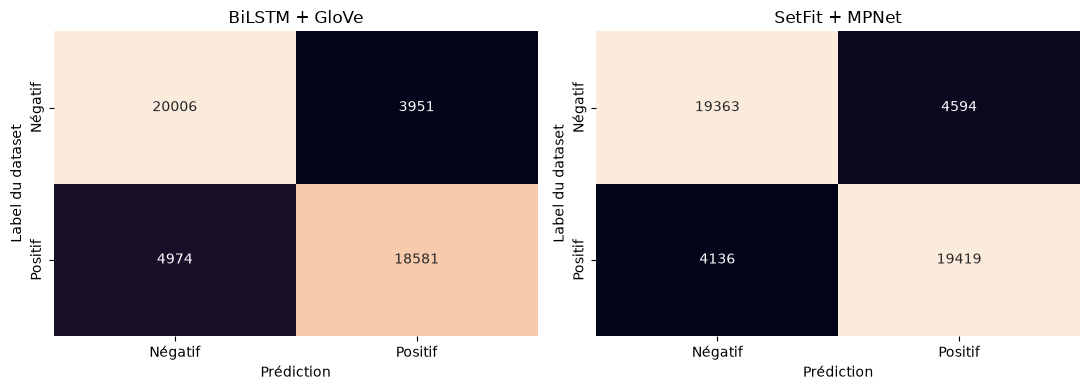

,tweet,label,prediction_bilstm,prediction_setfit
5903,@gingdottwit Happy Birthday Ashton Shame its ...,1,0,0
38323,Hanging out at the hospital is much more fun w...,0,1,1
21788,@JayGreasley Pooh I was hoping to do some vid...,0,0,1
18828,@alisonhaislip mines a bowl of cereal and the ...,0,0,1
27830,@josaay Darn you for seeing Adam! you always do!,0,1,1
36183,@melissaWOOF text me what happens once you cal...,1,1,0
9692,@4_inch_heels funny but fugly,0,0,1
458,is really enjoying TweetDeck for the iPod Touc...,0,0,1
9114,@PrincessVickie I think she's too brash and ru...,1,0,0
15658,Ate just used my twitter! So the last update w...,1,0,0


In [44]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for axis, (name, predictions) in zip(axes, models_predictions.items()):
    sns.heatmap(confusion_matrix(y_test, predictions), annot=True, fmt="d", cbar=False,
                xticklabels=["Négatif", "Positif"], yticklabels=["Négatif", "Positif"], ax=axis)
    axis.set(title=name, xlabel="Prédiction", ylabel="Label du dataset")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "matrices_confusion.png", dpi=160)
plt.show()

errors_setfit = predictions_test[predictions_test["label"] != predictions_test["prediction_setfit"]]
display(errors_setfit.sample(min(10, len(errors_setfit)), random_state=SEED))

## Interprétabilité locale et globale

Les coefficients de la tête portent sur les dimensions des embeddings, pas directement sur les mots. On retire donc un mot à la fois :

$$\Delta_w(x)=p(positif\mid x)-p(positif\mid x\setminus w).$$

Une variation positive indique que la présence du mot soutient le positif dans cette phrase ; une variation négative soutient le négatif. L'explication locale porte sur un tweet. La synthèse globale est la moyenne de $|\Delta_w|$ sur les occurrences du mot dans 100 tweets équilibrés, avec au moins trois occurrences par mot.

Cette synthèse décrit un échantillon, pas tout le corpus. La suppression peut changer la grammaire et les probabilités ne sont pas calibrées : on ne mesure pas une causalité. Le nuage de mots du dashboard montre des fréquences, pas cette importance.


In [45]:
def expliquer_tweet(model, tweet):
    text = clean_tweet_SETFIT(tweet)
    words = text.split()
    variants = [text] + [" ".join(words[:i] + words[i + 1:]) for i in range(len(words))]
    probabilities = np.asarray(model.predict_proba(variants))[:, 1]
    return pd.DataFrame({
        "mot": words,
        "variation_probabilite_positive": probabilities[0] - probabilities[1:],
    })

explanation_sample = df_test.groupby("label", group_keys=False).sample(n=50, random_state=SEED)
local_explanations = []
for index, row in explanation_sample.iterrows():
    explanation = expliquer_tweet(model_setfit, row["tweet"])
    explanation["tweet_index"] = index
    explanation["label"] = row["label"]
    local_explanations.append(explanation)
local_explanations = pd.concat(local_explanations, ignore_index=True)
local_explanations.to_csv(RESULTS_DIR / "explications_locales.csv", index=False)

global_explanations = local_explanations.assign(
    variation_absolue=lambda data: data["variation_probabilite_positive"].abs()
).groupby("mot").agg(
    variation_moyenne=("variation_absolue", "mean"),
    occurrences=("mot", "size"),
).query("occurrences >= 3").sort_values("variation_moyenne", ascending=False)
global_explanations.head(20).to_csv(RESULTS_DIR / "importance_mots.csv")
display(global_explanations.head(10))
for index in explanation_sample.head(4).index:
    print(df_test.loc[index, "tweet"])
    display(local_explanations[local_explanations["tweet_index"] == index].sort_values(
        "variation_probabilite_positive", key=lambda values: values.abs(), ascending=False
    ).head(5))

,variation_moyenne,occurrences
mot,,
see,0.346285,3
down,0.332500,3
didn't,0.332159,3
when,0.329002,3
want,0.325777,3
You,0.301321,3
!,0.268607,6
while,0.264777,3
will,0.262900,3


Checking out post-examinations activities, so many Economics and Geography supplementary classes 


,mot,variation_probabilite_positive,tweet_index,label
0,Checking,0.000073,13852,0
5,many,-0.000017,13852,0
4,so,-0.000008,13852,0
10,classes,-0.000008,13852,0
9,supplementary,-0.000007,13852,0


... i can leave work after this game ends. how long does a soccer game takeeee?? 


,mot,variation_probabilite_positive,tweet_index,label
26,takee??,-0.994705,8287,0
20,how,-0.668162,8287,0
21,long,-0.001172,8287,0
16,after,0.000809,8287,0
22,does,-0.000661,8287,0


My Favourite website is down 


,mot,variation_probabilite_positive,tweet_index,label
31,down,-0.996070,18435,0
29,website,-0.995931,18435,0
30,is,-0.008521,18435,0
28,Favourite,-0.000238,18435,0
27,My,0.000041,18435,0


Don't eat icecream while lying upside down...hurts your head 


,mot,variation_probabilite_positive,tweet_index,label
38,down..hurts,-0.001647,31993,0
34,icecream,0.000138,31993,0
39,your,0.000127,31993,0
37,upside,0.000075,31993,0
35,while,0.000060,31993,0


## Conclusion

Sur les mêmes 47 512 tweets, le F1 macro est de 0,8120 pour le BiLSTM et de 0,8163 pour SetFit, soit un gain modeste de 0,427 point. SetFit utilise 1 024 tweets de train contre 300 000, mais son inférence est plus lente dans les mesures réalisées.

Les labels sont automatiques et anciens. Les nettoyages, budgets de train et tailles de validation diffèrent ; un seul entraînement est disponible par modèle. La validation initiale contient aussi 421 textes bruts présents dans le train. Le filtrage du test réduit les fuites observables sans garantir une indépendance par auteur ou par période.

Les suites utiles sont des partitions nettoyées avant entraînement, des budgets identiques, plusieurs graines et un nouveau test annoté manuellement. Pour l'interprétabilité, on élargirait l'échantillon et vérifierait la stabilité des effets de mots. Les anciens calculs d'incertitude restent archivés dans Results ; ils ne sont pas nécessaires à la présentation principale.
